# Kategori yang Belum Digarap: Penetration Gap sebagai Proxy Satu Retailer

Data hanya dari satu retailer, jadi tidak ada cara mengetahui ke mana sisa dompet member pergi. Yang bisa dilakukan — dan dilakukan di sini — adalah membandingkan setiap member dengan peer yang paling sebanding: kalau sebagian besar peer rajin membeli satu kategori sementara member ini tidak pernah, itulah kategori yang *mungkin* belum digarap. Semua angka di notebook ini karenanya berlabel **proxy dalam satu retailer** — bukan ukuran total dompet lintar retailer. Definisi formalnya tercatat di `docs/decision-log.md`.

Output akhirnya praktis: daftar top-10 kategori kandidat per member, diurutkan berdasarkan potensi spend (`expected_spend`) — bahan langsung untuk rekomendasi targeting dan tabel segmen.

## 0. Setup

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import pandas as pd

from src.cohorts import build_cohort_benchmarks, build_cohorts, build_whitespace
from src.features import PROCESSED_DIR, save_parquet

hh_cat = pd.read_parquet(PROCESSED_DIR / "hh_category.parquet")
cohorts, merge_log = build_cohorts(hh_cat)
bench = build_cohort_benchmarks(hh_cat, cohorts)
ws = build_whitespace(hh_cat, cohorts, bench)
print(f"hh_category: {len(hh_cat):,} baris | {hh_cat['household_key'].nunique():,} member | {hh_cat['commodity_desc'].nunique()} komoditas")

hh_category: 288,690 baris | 2,500 member | 308 komoditas


## 1. Membandingkan dengan yang sebanding

Membandingkan member hemat dengan pembelanja rakus hanya akan menghasilkan daftar kategori yang panjang dan tidak berguna. Cohort membagi member menjadi tiga tercile total spend × tiga tercile ragam kategori — pembanding yang cukup mirip untuk bermakna, cukup besar untuk stabil.

Grid 3×3 di data ini tidak terisi penuh, dan itu sendiri informasi: tidak ada member dengan spend kecil tapi ragam kategori luas (S1xB3 kosong), dan hanya empat member dengan spend besar tapi ragam sempit — mereka digabungkan ke cohort tetangga agar ukuran selnya tetap layak dilaporkan.

In [2]:
if merge_log:
    print("penggabungan sel kecil:", "; ".join(merge_log))
sizes = (
    cohorts.groupby("cohort")
    .agg(
        n=("household_key", "size"),
        mean_spend=("total_net_spend", "mean"),
        mean_breadth=("n_commodities", "mean"),
    )
    .round(1)
    .sort_values("cohort")
)
display(sizes)
print(f"7 cohort | n terkecil {int(sizes['n'].min())} — jauh di atas batas pelaporan sel (n >= 30)")

penggabungan sel kecil: S3xB1 (n=4) merged into S2xB1


,n,mean_spend,mean_breadth
cohort,,,
S1xB1,707,456.9,60.0
S1xB2,127,843.5,106.4
S2xB1,127,1562.5,81.6
S2xB2,579,1751.7,118.1
S2xB3,131,2187.7,148.0
S3xB2,127,3882.4,126.6
S3xB3,702,5963.6,168.8


7 cohort | n terkecil 127 — jauh di atas batas pelaporan sel (n >= 30)


## 2. Share kategori dan median cohort

Share sebuah kategori = porsi spend kategori itu dari total spend member. Benchmark-nya **median di antara pembeli kategori tersebut dalam cohort** — bukan median seluruh anggota, yang akan jatuh ke nol untuk kategori dengan penetrasi di bawah 50% dan membatalkan maksud perbandingan.

Sebagai kategori kandidat whitespace hanya dipakai yang dibeli minimal 30% anggota cohort: kategori niche yang hanya dibeli segelintir orang bukan "ruang kosong", melainkan selera khusus.

kategori kandidat per cohort (dari 308 komoditas): {'S1xB1': 81, 'S1xB2': 146, 'S2xB1': 111, 'S2xB2': 154, 'S2xB3': 186, 'S3xB2': 157, 'S3xB3': 211}


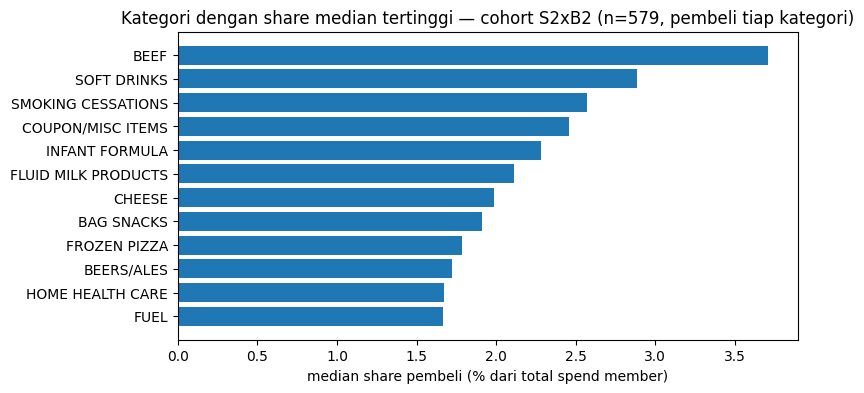

In [3]:
eligible = bench[(bench["buyer_rate"] >= 0.30) & (bench["median_share"] > 0)]
print(
    "kategori kandidat per cohort (dari 308 komoditas):",
    eligible.groupby("cohort").size().to_dict(),
)

mid = bench[bench["cohort"] == "S2xB2"].sort_values("median_share", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(mid["commodity_desc"], mid["median_share"] * 100, color="#1f77b4")
ax.invert_yaxis()
ax.set(
    title="Kategori dengan share median tertinggi — cohort S2xB2 (n=579, pembeli tiap kategori)",
    xlabel="median share pembeli (% dari total spend member)",
    ylabel="",
)
plt.show()

## 3. Whitespace per member

Satu pasangan (member, kategori) disebut whitespace bila member tidak pernah membeli kategori itu, atau share-nya di bawah separuh median cohort. Prioritasnya diurutkan dengan `expected_spend` = median share cohort × total spend member — potensi tahunan kira-kira, bukan janji.

Setiap member di data ini punya minimal sepuluh kandidat (daftar top-10 selalu terisi penuh), dan hampir separuh entrinya adalah kategori yang belum pernah disentuh sama sekali.

In [4]:
save_parquet(ws, PROCESSED_DIR / "hh_whitespace.parquet")
save_parquet(bench, PROCESSED_DIR / "cohort_category.parquet")
print(
    f"{len(ws):,} baris whitespace ({ws['household_key'].nunique():,} member × top-10) | "
    f"zero-buyer: {ws['is_zero_buyer'].mean():.1%} | "
    f"expected_spend: p50 ${ws['expected_spend'].median():.1f} | p99 ${ws['expected_spend'].quantile(.99):.0f} | max ${ws['expected_spend'].max():.0f}"
)

spot = ws[ws["household_key"] == 1023].head(5)
display(spot[["commodity_desc", "hh_share", "cohort_median_share", "is_zero_buyer", "expected_spend"]].round(3))
print("contoh member 1023 (cohort S3xB3): SOFT DRINKS dibeli, tapi porsinya 0,7% vs median peer 2,5% — kandidat dorong, bukan kandidat buka.")

25,000 baris whitespace (2,500 member × top-10) | zero-buyer: 48.8% | expected_spend: p50 $18.5 | p99 $268 | max $1281


,commodity_desc,hh_share,cohort_median_share,is_zero_buyer,expected_spend
10220,SOFT DRINKS,0.007,0.025,False,896.083
10221,BAG SNACKS,0.007,0.016,False,593.432
10222,BAKED BREAD/BUNS/ROLLS,0.004,0.015,False,534.857
10223,DIAPERS & DISPOSABLES,0.000,0.013,True,475.566
10224,FRZN MEAT/MEAT DINNERS,0.001,0.013,False,463.319


contoh member 1023 (cohort S3xB3): SOFT DRINKS dibeli, tapi porsinya 0,7% vs median peer 2,5% — kandidat dorong, bukan kandidat buka.


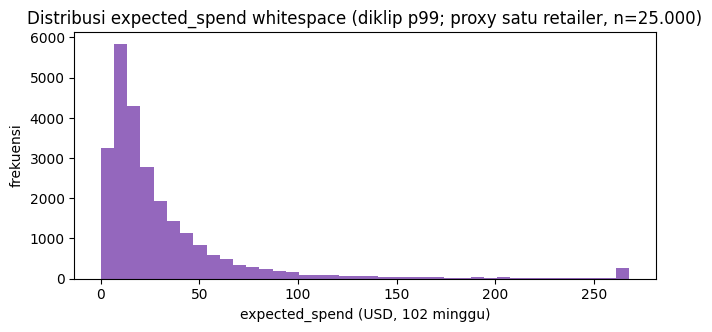

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(ws["expected_spend"].clip(upper=ws["expected_spend"].quantile(0.99)), bins=40, color="#9467bd")
ax.set(
    title="Distribusi expected_spend whitespace (diklip p99; proxy satu retailer, n=25.000)",
    xlabel="expected_spend (USD, 102 minggu)",
    ylabel="frekuensi",
)
plt.show()

## 4. Peluang agregat — tetap sebuah proxy

Dilihat lintas member, kategori whitespace terbesar adalah barang-barang belanja inti: daging, bir, minuman, popok. Satu peringatan interpretasi menempel di posisi pertama: **COUPON/MISC ITEMS** adalah kategori operator (item terkait kupon), bukan produk — masuk daftar karena transaksinya besar dan tersebar, dan sebaiknya dikecualikan saat dipakai untuk rekomendasi produk.

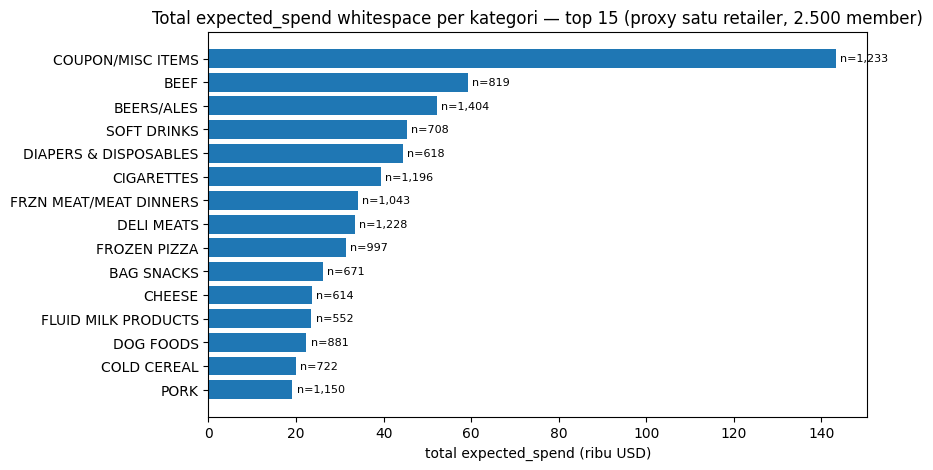

,n_member,total_expected
cohort,,
S3xB3,702,489569.0
S2xB2,579,128092.0
S1xB1,707,72694.0
S3xB2,127,63166.0
S2xB3,131,33061.0
S2xB1,127,31298.0
S1xB2,127,15007.0


In [6]:
top = (
    ws.groupby("commodity_desc")
    .agg(n_member=("household_key", "size"), total_expected=("expected_spend", "sum"))
    .sort_values("total_expected", ascending=False)
    .head(15)
)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(top.index, top["total_expected"] / 1e3, color="#1f77b4")
ax.invert_yaxis()
ax.set(
    title="Total expected_spend whitespace per kategori — top 15 (proxy satu retailer, 2.500 member)",
    xlabel="total expected_spend (ribu USD)",
    ylabel="",
)
for i, (idx, row) in enumerate(top.iterrows()):
    ax.text(row["total_expected"] / 1e3 + 1, i, f"n={int(row['n_member']):,}", va="center", fontsize=8)
plt.show()

per_cohort = ws.groupby("cohort").agg(
    n_member=("household_key", "nunique"), total_expected=("expected_spend", "sum")
).round(0).sort_values("total_expected", ascending=False)
per_cohort

## 5. Artefak & angka kunci

In [7]:
display(pd.DataFrame(
    [(a, f"{(PROCESSED_DIR / a).stat().st_size / 1e6:.1f} MB") for a in ("hh_whitespace.parquet", "cohort_category.parquet")],
    columns=["artefak (data/processed/)", "ukuran"],
))
print(
    f"7 cohort (n terkecil 127) | 25.000 baris whitespace (top-10 × 2.500 member) | "
    f"zero-buyer {ws['is_zero_buyer'].mean():.1%} | kategori kandidat 81–211 per cohort"
)

,artefak (data/processed/),ukuran
0,hh_whitespace.parquet,0.5 MB
1,cohort_category.parquet,0.0 MB


7 cohort (n terkecil 127) | 25.000 baris whitespace (top-10 × 2.500 member) | zero-buyer 48.8% | kategori kandidat 81–211 per cohort


## Catatan kualitas & batasan

- Semua angka adalah **proxy dalam satu retailer** — tidak mengatakan apa pun tentang belanja member di luar retailer ini.
- Benchmark memakai median di antara pembeli kategori (bukan seluruh anggota cohort); kategori kandidat difilter pembeli ≥ 30% anggota cohort; ambang deficit 50% dari median.
- COUPON/MISC ITEMS adalah kategori operator dan muncul sebagai whitespace terbesar — ditandai di sini dan selayaknya dikecualikan dari rekomendasi produk.
- `expected_spend` adalah potensi deskriptif berbasis median cohort, bukan prediksi kausal: member yang tidak membeli sebuah kategori bisa saja membelinya di kompetitor, atau memang tidak membutuhkannya.
- Semua nominal USD historis; tidak ada klaim kausal di notebook ini.